In [1]:
import sys
import importlib

from pathlib import Path
project_root = Path.cwd().parent    # notebooks -> project_root
sys.path.insert(0, str(project_root))
print(project_root)

from matplotlib import pyplot as plt
import numpy as np

/Users/tcui0786/Work/DeepTransport/PyFInS-public


In [2]:
import BaseModels
importlib.reload(BaseModels)

import NumpyModels.ConditionedDiffusion
importlib.reload(NumpyModels.ConditionedDiffusion)

import NumpyModels.DerivativeTests
importlib.reload(NumpyModels.DerivativeTests)

<module 'NumpyModels.DerivativeTests' from '/Users/tcui0786/Work/DeepTransport/PyFInS-public/NumpyModels/DerivativeTests.py'>

In [3]:
from NumpyModels.ConditionedDiffusion import ConditionedDiffusion, BrownianPrior, load_conditioned_diffusion_problem
prior, model, like, true_w = load_conditioned_diffusion_problem("../NumpyModels/CDsetup.mat")
from NumpyModels.DerivativeTests import test_combined
test_combined(prior, model, n_tests=50)

Solver and prior derivative tests
  number of tests : 50
  epsilon         : 1.000e-06

test                             mean relative error    max relative error
--------------------------------------------------------------------------
prior L/L.T adjoint                     6.024890e-15          2.129464e-13
prior inverse                           1.658595e-15          5.446769e-15
physical Jacobian                       5.380401e-09          1.743160e-08
physical adjoint                        2.157199e-15          6.585335e-14
whitened Jacobian                       2.688805e-08          9.272594e-08
whitened adjoint                        6.649749e-15          1.955167e-13


## Conditioned diffusion model

We consider a one-dimensional diffusion $u_t$ evolving in a double-well potential,
$$
du_t = f(u_t)\,dt + dw_t,
\qquad u_0 = 0,
$$
where $w_t$ is a standard Brownian motion and
$$
f(u)
=
\beta u \frac{1-u^2}{1+u^2},
\qquad \beta > 0.
$$

A possible inverse problem (implemented here) treats the driving Brownian path $w$ as the unknown parameter. Its prior is Wiener measure,
$$
w \sim \mathcal{N}(0,\mathcal{C}),
\qquad
\mathcal{C}(s,t) = \min(s,t).
$$
Given a realization of $w$, the diffusion trajectory $u$ is determined by the SDE. Thus, the forward map has the form
$$
w \longmapsto u.
$$
Alternatively, we can also treat $u$ as the unknown parameter, which naturally follow a Markov structure. 

### Time discretization and Markov structure

Let $t_n = n\Delta t, n=0,\ldots,N,$ and denote
$$
w_n = w(t_n),
\qquad
u_n = u(t_n).
$$
The Euler--Maruyama discretization gives
$$
u_{n+1}
=
u_n + \Delta t\,f(u_n) + (w_{n+1}-w_n).
$$
Defining the Brownian increments
$$
\Delta w_n = w_{n+1}-w_n,
$$
we have
$$
\Delta w_n \sim \mathcal{N}(0,\Delta t),
$$
independently over $n$. Hence,
$$
u_{n+1}
=
u_n + \Delta t\,f(u_n) + \Delta w_n.
$$
This representation makes the temporal Markov structure explicit. In particular,
$$
u_{n+1} \mid (u_0,\ldots,u_n)
\overset{d}{=}
u_{n+1} \mid u_n,
$$
with transition distribution
$$
u_{n+1} \mid u_n
\sim
\mathcal{N}
\left(
u_n + \Delta t\,f(u_n),
\Delta t
\right).
$$
Thus, the physical states form a first-order Markov chain in time,
$$
u_0
\longrightarrow
u_1
\longrightarrow
u_2
\longrightarrow
\cdots
\longrightarrow
u_N.
$$



### Brownian increments 

The Brownian increments provide independent innovations at each transition. Equivalently, introducing independent standard Gaussian variables
$$
\xi_n \overset{\mathrm{iid}}{\sim} \mathcal{N}(0,1),
$$
we can write
$$
\Delta w_n = \sqrt{\Delta t}\,\xi_n,
$$
and therefore
$$
u_{n+1}
=
u_n + \Delta t\,f(u_n)
+ \sqrt{\Delta t}\,\xi_n.
$$
The unknown represented in the inverse problem is the Brownian path
$$
w = (w_1,\ldots,w_N),
$$
rather than its independent increments. The path values $w_n$ are correlated in time, with
$$
\operatorname{Cov}(w_i,w_j)
=
\min(t_i,t_j),
$$
whereas the increments $\Delta w_n$ are mutually independent. The Brownian path can equivalently be generated from the independent Gaussian variables $\xi_n$ according to
$$
w_n
=
\sqrt{\Delta t}
\sum_{j=0}^{n-1} \xi_j.
$$


### Conditioning on observations

Noisy observations of the diffusion state are made at selected times,
$$
y_i = u_{n_i} + e_i,
\qquad
e_i \sim \mathcal{N}(0,\sigma^2).
$$
The underlying state-space model therefore admits the factorization
$$
p(u_{0:N},y)
=
p(u_0)
\prod_{n=0}^{N-1}
p(u_{n+1}\mid u_n)
\prod_i
p(y_i\mid u_{n_i}).
$$
Although the physical states $u_n$ form a Markov chain under the forward model, the inverse problem is parameterized by the driving Brownian path $w$. The complete hierarchy can therefore be summarized as


In [4]:
from NumpyInference import LikelihoodInformedSMC, LikelihoodInformedSubspace
from InferenceTools.TransitionKernels import OneStepKernel

kernel = OneStepKernel(
        type="OW",
        sigma=-3.0,
        adapt=True,
        nbatch=1,
)

LIS = LikelihoodInformedSubspace(epsilon=0.1)

sampler = LikelihoodInformedSMC(
        prior,
        model,
        like,
        LIS,
        kernel,
        max_iter=100,
        n_samples=1000,
        n_mutation_steps=20,
        n_final_mutation_steps=100, # n_samples times the final mutation steps give the total number of samples 
        ess_tol=0.5,
        min_beta=1e-6,
        pm_sample_size=5,
)

sampler.iterate()

iteration 0
Start model evaluations


100%|██████████| 1000/1000 [00:00<00:00, 1753.50it/s]


Total time for model evaluations is 0.5901224999688566
temperature 0.014226649032170866, ess 0.49829449112672347, log const -2.3817413655193804
LIS dimension 19


MCMC: 100%|██████████| 20/20 [00:33<00:00,  1.69s/it, acc_rate=0.810, sigma=-2.00000]


iteration 1
Start model evaluations



100%|██████████| 1000/1000 [00:00<00:00, 1804.91it/s]


... (18 outputs left out)


iteration 6
Start model evaluations



100%|██████████| 1000/1000 [00:00<00:00, 1812.95it/s]


Total time for model evaluations is 0.5530555829755031
temperature 1.0, ess 0.4960861282540929, log const -7.309889465035134
LIS dimension 116


MCMC: 100%|██████████| 100/100 [03:17<00:00,  1.98s/it, acc_rate=0.475, sigma=-3.40000]


(100, 1000, 1000)


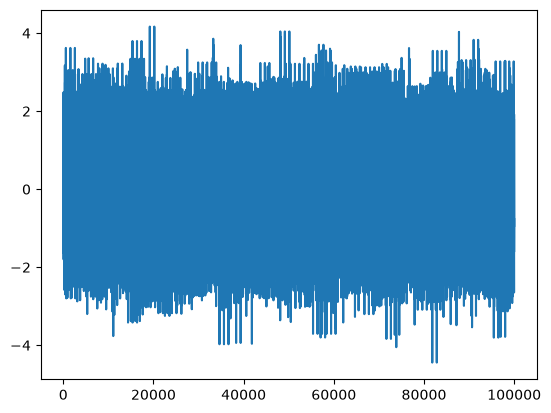

In [ ]:
# 100 iterations, 1000 samples, and 1000 dimension
X = sampler.xi_data[-1].reshape(-1, sampler.xi_data[-1].shape[-1])

# plot the first parameter dimension
plt.plot(X[:,1])